<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/1_1_matrix_as_linear_map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.1 · A matrix as a linear map

*Phase 1 — linear algebra for interpretability*

Before we can say anything about what a neural network has learned, we need a precise picture of what a weight matrix *does*. This notebook builds that picture one step at a time, and ends on the question the rest of Phase 1 grows from: **is there a direction that a matrix only stretches, and never turns?**

Each step is a short note followed by a single experiment cell. Run them in order and change the numbers freely; every cell is small enough to break on purpose. All the numerics are PyTorch. Matplotlib is only used to draw.

1. A matrix is a function
2. Linearity, and what the columns mean
3. Watching a grid get transformed
4. Searching for directions that aren't turned
5. Eigenvectors and eigenvalues, computed
6. The eigenbasis: where the matrix is just scaling
7. Reading an eigenvalue
8. When the picture breaks
9. Repeated application: the dominant eigenvector wins

## Setup

We work in double precision, since eigenvalue checks are far more readable at 1e-15 than at 1e-7. The colours are fixed for the whole notebook: grey for the input space, blue for what the matrix produces, orange and purple for the two eigenvectors.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

# Fixed roles for colour, used consistently below
C_IN, C_OUT = "#6b7280", "#2563eb"          # input space (grey), transformed output (blue)
C_V1, C_V2 = "#d97706", "#9333ea"           # first and second eigenvector (orange, purple)
EIG_COLORS = [C_V1, C_V2]

print("torch", torch.__version__)

torch 2.11.0+cpu


## Step 1 · A matrix is a function

A 2×2 matrix $A$ takes a vector $x$ in the plane and returns another vector $Ax$. That is all it is. We'll use one matrix for most of this notebook, chosen so the numbers come out clean:

$$A = \begin{pmatrix} 2 & 1 \\ 0.5 & 1.5 \end{pmatrix}$$



In [2]:
A = torch.tensor([[2.0, 1.0],
                  [0.5, 1.5]])

xs = torch.tensor([[ 1.0, 0.0],
                   [ 0.0, 1.0],
                   [ 1.0, 1.0],
                   [-1.0, 2.0]])            # each row is one input vector

for x in xs:
    print(f"x = {x.tolist()!s:>12}   →   A @ x = {(A @ x).tolist()}")

x =   [1.0, 0.0]   →   A @ x = [2.0, 0.5]
x =   [0.0, 1.0]   →   A @ x = [1.0, 1.5]
x =   [1.0, 1.0]   →   A @ x = [3.0, 2.0]
x =  [-1.0, 2.0]   →   A @ x = [0.0, 2.5]


## Step 2 · Linearity, and what the columns mean

What makes matrices worth studying is that they are *linear*:

$$A(a\,x + b\,y) = a\,Ax + b\,Ay$$

Two things follow. First, a matrix is completely determined by what it does to the basis vectors, because every other vector is a combination of them. The columns of $A$ are exactly the images of $e_1$ and $e_2$. Second, straight lines stay straight and the origin stays fixed, so the only things a matrix can do to space are stretch, shear, rotate, reflect and squash.

Let's confirm both claims numerically.

• torch.eye(2) generates a \(2 \* 2\) identity matrix:

\begin{pmatrix}1&0\\ 0&1\end{pmatrix}

• Python unpacks this matrix by row.

• e1 gets the first row: [1., 0.] (the unit vector pointing along the X-axis).

• e2 gets the second row: [0., 1.] (the unit vector pointing along the Y-axis).

In [4]:
e1, e2 = torch.eye(2)                         # the standard basis vectors

print("A @ e1 =", (A @ e1).tolist(), "   first column of A: ", A[:, 0].tolist())
print("A @ e2 =", (A @ e2).tolist(), "   second column of A:", A[:, 1].tolist())

# Linearity on random vectors and scalars
x, y = torch.randn(2), torch.randn(2)
a, b = 1.7, -0.6
lhs = A @ (a * x + b * y)
rhs = a * (A @ x) + b * (A @ y)
print("\nlinearity residual:", (lhs - rhs).abs().max().item())

assert torch.allclose(A @ e1, A[:, 0]) and torch.allclose(A @ e2, A[:, 1])
assert torch.allclose(lhs, rhs)
print("✓ columns are the images of the basis vectors, and A is linear")

A @ e1 = [2.0, 0.5]    first column of A:  [2.0, 0.5]
A @ e2 = [1.0, 1.5]    second column of A: [1.0, 1.5]

linearity residual: 0.0
✓ columns are the images of the basis vectors, and A is linear


## Step 3 · Watching a grid get transformed

Numbers are hard to hold in your head, but shapes are easy. Take a square lattice and the unit circle, push every point through $A$, and look at the result. Because $A$ is linear, lattice lines stay straight and parallel, and the circle becomes an ellipse. The black arrows show where the two basis vectors land, which are the columns of $A$ from the last step.

We define the drawing helpers here and reuse them for the rest of the notebook.

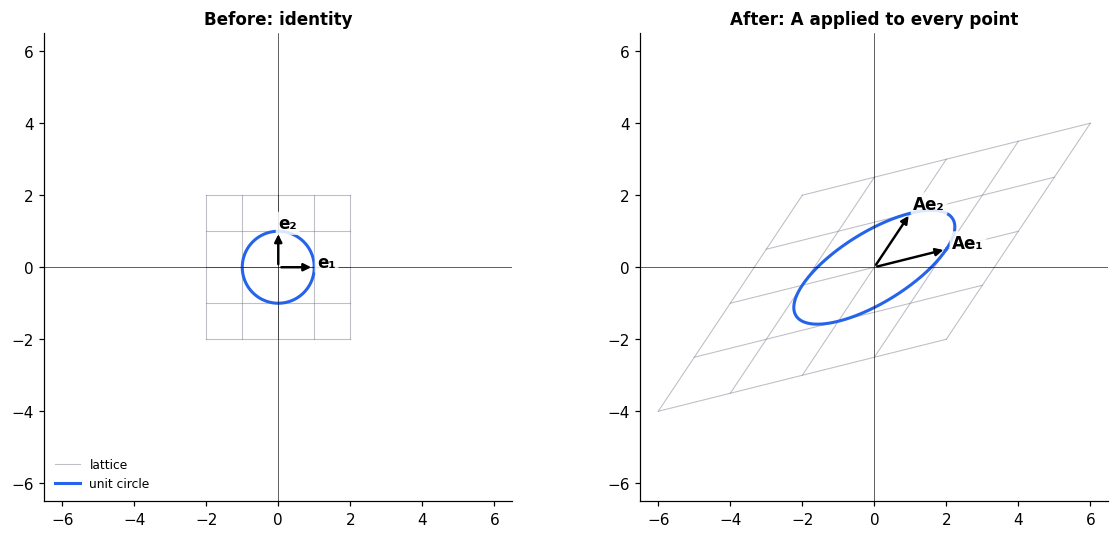

In [10]:
def grid_segments(lim=2, n=41):
    """Lattice lines x = k and y = k for integer k in [-lim, lim], each as a (2, n) tensor of points."""
    t = torch.linspace(-lim, lim, n)
    ones = torch.ones(n)
    segs = []
    for k in range(-lim, lim + 1):
        segs.append(torch.stack([k * ones, t]))      # vertical line   x = k
        segs.append(torch.stack([t, k * ones]))      # horizontal line y = k
    return segs

theta = torch.linspace(0, 2 * math.pi, 400)
circle = torch.stack([theta.cos(), theta.sin()])     # unit circle, shape (2, 400)


def draw_space(ax, M, title, lim=6.5, basis_labels=None, legend=False):
    """Draw the lattice and the unit circle after applying M. Pass the identity for 'before'."""
    for i, s in enumerate(grid_segments()):
        p = M @ s
        ax.plot(p[0], p[1], color=C_IN, lw=0.7, alpha=0.45, label="lattice" if i == 0 else None)
    c = M @ circle
    ax.plot(c[0], c[1], color=C_OUT, lw=2, label="unit circle")
    if basis_labels:
        for j, name in enumerate(basis_labels):
            tip = M[:, j].tolist()
            ax.annotate("", xy=tip, xytext=(0, 0),
                        arrowprops=dict(arrowstyle="-|>", color="black", lw=1.6), zorder=5)
            ax.text(tip[0] * 1.08, tip[1] * 1.08, name, fontsize=11, weight="bold", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal"); ax.grid(False)
    ax.axhline(0, color="k", lw=0.4); ax.axvline(0, color="k", lw=0.4)
    ax.set_title(title)
    if legend:
        ax.legend(loc="lower left", fontsize=8, frameon=False)


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_space(axes[0], torch.eye(2), "Before: identity", basis_labels=("e₁", "e₂"), legend=True)
draw_space(axes[1], A, "After: A applied to every point", basis_labels=("Ae₁", "Ae₂"))
plt.tight_layout(); plt.show()

## Step 4 · Searching for directions that aren't turned

In the picture above, most directions get both stretched and turned. So here is the question that matters: is there any direction $v$ for which $Av$ lands back on the same line as $v$? If so, $A$ treats that direction as pure scaling:

$$A v = \lambda v$$

We call $v$ an **eigenvector** and the scale factor $\lambda$ its **eigenvalue**. Before reaching for the formula, let's find these directions by brute-force search. For each direction $\theta$ we measure the angle between a unit vector $u(\theta)$ and its image $Au(\theta)$. Wherever that angle is zero, the matrix is not turning that direction.

Directions from 0° to 180° cover every line through the origin, since $\theta$ and $\theta+180°$ are the same line. The angle is folded into $(-90°, 90°]$ so that a flip through the origin (a negative eigenvalue) would still count as staying on the line.

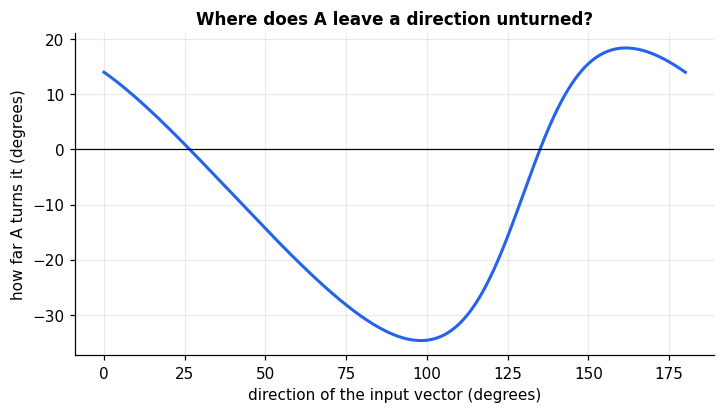

directions A does not turn (degrees): [26.5, 135.0]


In [11]:
def deflection(M, theta):
    """Angle (radians) by which M turns the direction at angle theta, folded so a flip counts as 'no turn'."""
    u = torch.stack([theta.cos(), theta.sin()])          # (2, N) unit vectors
    Mu = M @ u
    cross = u[0] * Mu[1] - u[1] * Mu[0]                   # ∝ sin of the turn
    dot = (u * Mu).sum(0)                                 # ∝ cos of the turn
    d = torch.atan2(cross, dot)
    return d - math.pi * torch.round(d / math.pi)


thetas = torch.linspace(0, math.pi, 721)
d = deflection(A, thetas)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(torch.rad2deg(thetas), torch.rad2deg(d), color=C_OUT, lw=2)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("direction of the input vector (degrees)")
ax.set_ylabel("how far A turns it (degrees)")
ax.set_title("Where does A leave a direction unturned?")
plt.show()

# Locate the zero crossings (ignoring the artificial jump at ±90° that the folding creates)
idx = ((d[:-1] * d[1:] < 0) & (d[:-1].abs() < 0.5)).nonzero().flatten()
found = [round(math.degrees(thetas[i].item()), 1) for i in idx]
print("directions A does not turn (degrees):", found)

## Step 5 · Eigenvectors and eigenvalues, computed

The search found two special directions. Linear algebra gives them to us exactly. A non-zero solution of $(A - \lambda I)v = 0$ exists only when $A - \lambda I$ squashes some direction to zero, which means

$$\det(A - \lambda I) = 0 \quad\Longleftrightarrow\quad \lambda^2 - \operatorname{tr}(A)\,\lambda + \det(A) = 0$$

for a 2×2 matrix. `torch.linalg.eig` does this in general. It returns complex tensors because eigenvalues can be complex; here the imaginary parts are zero, so we keep the real parts.

We'll check three things: the numbers match the quadratic formula, the defining equation $Av = \lambda v$ holds to machine precision, and the eigenvector directions match what the search found, up to the search's 0.25° step size.

In [13]:
evals, evecs = torch.linalg.eig(A)                # complex dtype; eigenvectors are the columns of evecs
print("eigenvalues:", evals)
print("largest imaginary part:", evals.imag.abs().max().item())

lam = evals.real
V = evecs.real                                    # V[:, i] is the eigenvector for lam[i]
order = lam.argsort(descending=True)              # largest eigenvalue first, so results are predictable
lam, V = lam[order], V[:, order]

# The same eigenvalues from the characteristic polynomial
tr, det = torch.trace(A), torch.det(A)
disc = (tr ** 2 - 4 * det).sqrt()
by_hand = torch.stack([(tr + disc) / 2, (tr - disc) / 2])
print("by hand    :", by_hand)

# The defining property, one eigenvector at a time
for i in range(2):
    v = V[:, i]
    resid = (A @ v - lam[i] * v).norm().item()
    print(f"λ{i+1} = {lam[i]:.4f}   v{i+1} = {v.tolist()}   ‖Av − λv‖ = {resid:.1e}")
    assert resid < 1e-10
assert torch.allclose(lam, by_hand)

# Compare with the brute-force search from Step 4
angles = torch.rad2deg(torch.atan2(V[1], V[0])) % 180
print("eigenvector directions (degrees, mod 180):", [round(a, 1) for a in angles.tolist()])
print("search found                              :", found)

eigenvalues: tensor([2.5000+0.j, 1.0000+0.j])
largest imaginary part: 0.0
by hand    : tensor([2.5000, 1.0000])
λ1 = 2.5000   v1 = [0.8944271909999159, 0.4472135954999579]   ‖Av − λv‖ = 0.0e+00
λ2 = 1.0000   v2 = [-0.7071067811865475, 0.7071067811865475]   ‖Av − λv‖ = 0.0e+00
eigenvector directions (degrees, mod 180): [26.6, 135.0]
search found                              : [26.5, 135.0]


Now let's see it. The dashed lines are the eigen-directions. Each eigenvector's image stays on its own line: $v_1$ grows by a factor of $\lambda_1$ and $v_2$ is unchanged because $\lambda_2 = 1$.

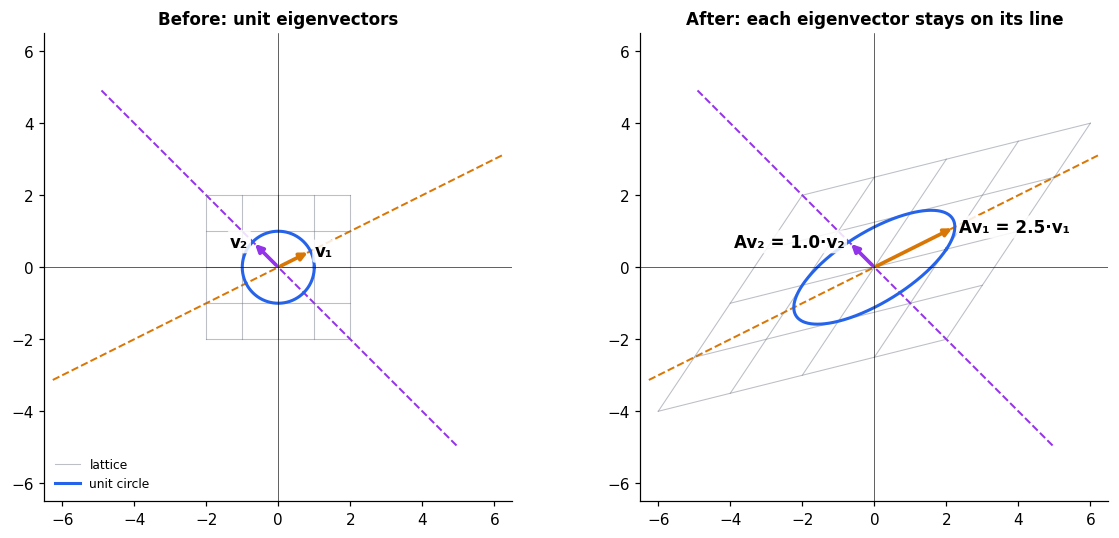

In [14]:
def draw_eigenlines(ax, V, length=7):
    """Dashed line through the origin along each eigenvector (the whole direction, not just one arrow)."""
    for i, col in enumerate(EIG_COLORS[: V.shape[1]]):
        v = V[:, i].tolist()
        ax.plot([-length * v[0], length * v[0]], [-length * v[1], length * v[1]],
                color=col, ls="--", lw=1.3, zorder=1)


def draw_vector(ax, v, label, color):
    tip = v.tolist()
    ax.annotate("", xy=tip, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.4), zorder=5)
    side = "left" if tip[0] >= 0 else "right"          # put the label on the outer side of the tip
    ax.text(tip[0] + (0.12 if tip[0] >= 0 else -0.12), tip[1], label, fontsize=11, weight="bold",
            ha=side, va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
draw_space(axes[0], torch.eye(2), "Before: unit eigenvectors", legend=True)
draw_space(axes[1], A, "After: each eigenvector stays on its line")
for ax in axes:
    draw_eigenlines(ax, V)
for i in range(2):
    draw_vector(axes[0], V[:, i], f"v{'₁₂'[i]}", EIG_COLORS[i])
    draw_vector(axes[1], A @ V[:, i], f"Av{'₁₂'[i]} = {lam[i]:.1f}·v{'₁₂'[i]}", EIG_COLORS[i])
plt.tight_layout(); plt.show()

## Step 6 · The eigenbasis: where the matrix is just scaling

Here is the deeper reason eigenvectors matter. Put the eigenvectors in the columns of $V$ and the eigenvalues on the diagonal of $\Lambda$. Then $AV = V\Lambda$ says that $A$ scales each column of $V$ by its eigenvalue, and multiplying on the right by $V^{-1}$ gives

$$A = V \Lambda V^{-1}$$

Read it right to left. $V^{-1}$ re-expresses a vector in eigenvector coordinates, $\Lambda$ scales each coordinate independently, and $V$ converts back to ordinary coordinates. In the right basis, a matrix is nothing more than a set of independent scalings. This idea of choosing the basis in which a transformation becomes simple is one we'll lean on again and again.

In [16]:
Lam = torch.diag(lam)
V_inv = torch.linalg.inv(V)

print("V Λ V⁻¹ (should equal A):\n", V @ Lam @ V_inv)
print("\nV⁻¹ A V (should be diagonal):\n", V_inv @ A @ V)
assert torch.allclose(V @ Lam @ V_inv, A)
assert torch.allclose(V_inv @ A @ V, Lam)

cos = (V[:, 0] @ V[:, 1]).abs()
print(f"\nangle between v₁ and v₂: {torch.rad2deg(torch.acos(cos)).item():.1f}°   (not perpendicular)")
print("✓ A = V Λ V⁻¹")

V Λ V⁻¹ (should equal A):
 tensor([[2.0000, 1.0000],
        [0.5000, 1.5000]])

V⁻¹ A V (should be diagonal):
 tensor([[ 2.5000,  0.0000],
        [-0.0000,  1.0000]])

angle between v₁ and v₂: 71.6°   (not perpendicular)
✓ A = V Λ V⁻¹


Now apply $A$ to one vector in three explicit stages and confirm it matches $Ax$.

In [17]:
x = torch.tensor([1.0, 2.0])

c = V_inv @ x               # 1) coordinates of x along v₁ and v₂
c_scaled = lam * c          # 2) scale each coordinate on its own
x_out = V @ c_scaled        # 3) back to ordinary coordinates

print("coordinates in the eigenbasis :", c)
print("after scaling by the λ's      :", c_scaled)
print("back in ordinary coordinates  :", x_out, "   vs   A @ x =", A @ x)
assert torch.allclose(x_out, A @ x)

coordinates in the eigenbasis : tensor([2.2361, 1.4142])
after scaling by the λ's      : tensor([5.5902, 1.4142])
back in ordinary coordinates  : tensor([4.0000, 3.5000])    vs   A @ x = tensor([4.0000, 3.5000])


The same thing as a picture. Draw a lattice whose axes run along $v_1$ and $v_2$ (a skewed grid, since the eigenvectors aren't perpendicular). Applying $A$ keeps every line of this lattice parallel to its original direction. The lines parallel to $v_1$ are stretched by $\lambda_1$ and the lines parallel to $v_2$ by $\lambda_2$, which is exactly what "diagonal in this basis" means.

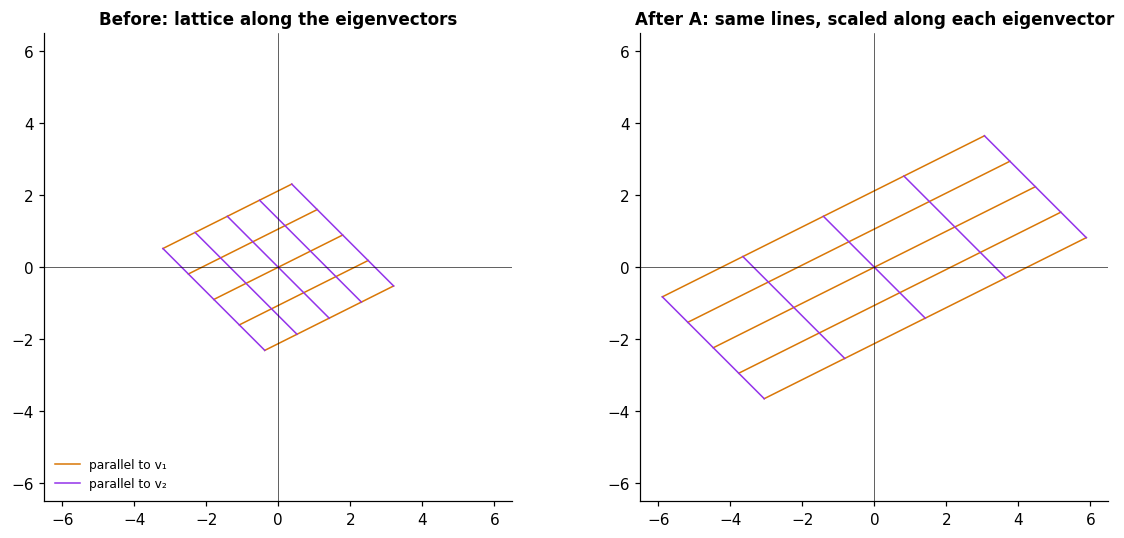

In [18]:
def eigen_lattice(V, scales=(1.0, 1.0), k=2, n=41):
    """Lines of the lattice {i·v₁ + j·v₂}, with the coordinates optionally scaled. Returns (parallel_to_v1, parallel_to_v2)."""
    t = torch.linspace(-k, k, n)
    ones = torch.ones(n)
    par_v1, par_v2 = [], []
    for m in range(-k, k + 1):
        par_v1.append(V @ torch.stack([scales[0] * t, scales[1] * m * ones]))   # coordinate along v₂ held fixed
        par_v2.append(V @ torch.stack([scales[0] * m * ones, scales[1] * t]))   # coordinate along v₁ held fixed
    return par_v1, par_v2


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, scales, title in [(axes[0], (1.0, 1.0), "Before: lattice along the eigenvectors"),
                          (axes[1], tuple(lam.tolist()), "After A: same lines, scaled along each eigenvector")]:
    par_v1, par_v2 = eigen_lattice(V, scales)
    for i, p in enumerate(par_v1):
        ax.plot(p[0], p[1], color=C_V1, lw=1.0, label="parallel to v₁" if i == 0 else None)
    for i, p in enumerate(par_v2):
        ax.plot(p[0], p[1], color=C_V2, lw=1.0, label="parallel to v₂" if i == 0 else None)
    ax.set_xlim(-6.5, 6.5); ax.set_ylim(-6.5, 6.5)
    ax.set_aspect("equal"); ax.grid(False); ax.set_title(title)
    ax.axhline(0, color="k", lw=0.4); ax.axvline(0, color="k", lw=0.4)
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## Step 7 · Reading an eigenvalue

The eigenvalue is the stretch factor along its eigenvector, sign included:

- $|\lambda| > 1$ stretches that direction, and $|\lambda| < 1$ shrinks it.
- $\lambda < 0$ flips the direction through the origin.
- $\lambda = 0$ collapses the direction onto the origin entirely, so information along it is lost.

To isolate the effect of the eigenvalues, we'll keep the eigenvectors of $A$ fixed and rebuild the matrix as $V\Lambda V^{-1}$ with different choices of $\Lambda$. Step 6 is why this construction works.

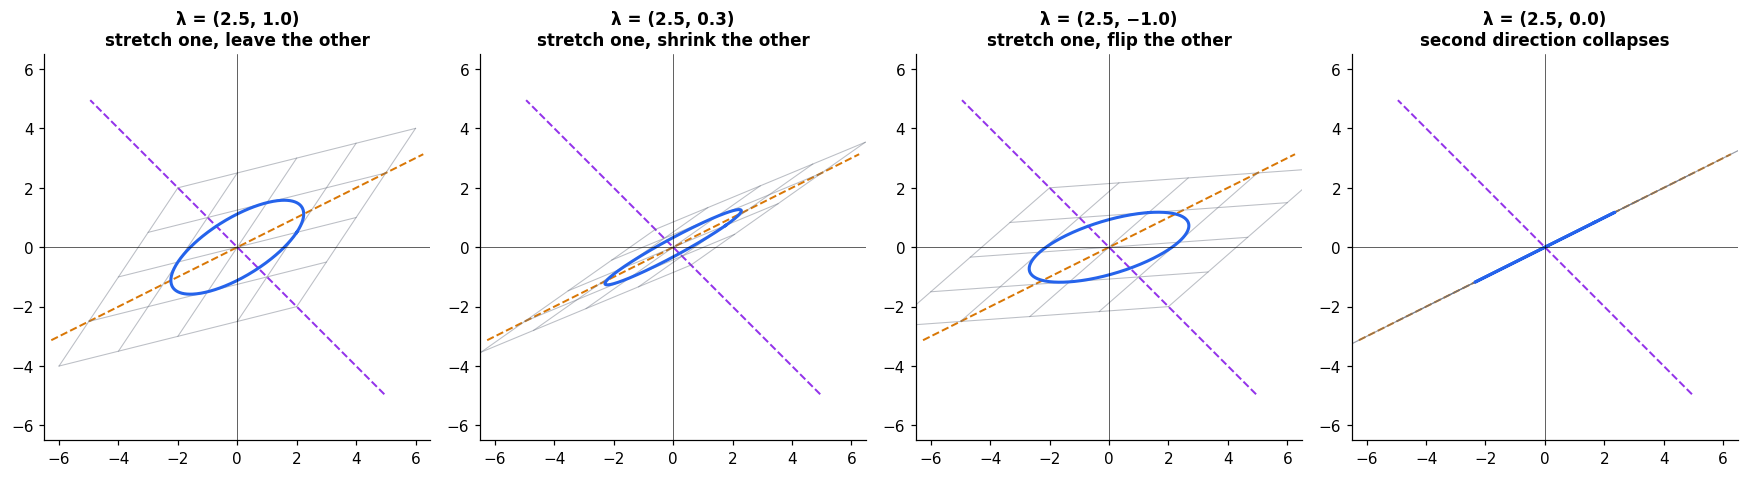

In [19]:
def from_eigen(V, lams):
    """The matrix that scales by lams[i] along column i of V."""
    return V @ torch.diag(torch.as_tensor(lams)) @ torch.linalg.inv(V)


cases = [
    ("λ = (2.5, 1.0)\nstretch one, leave the other", (2.5, 1.0)),
    ("λ = (2.5, 0.3)\nstretch one, shrink the other", (2.5, 0.3)),
    ("λ = (2.5, −1.0)\nstretch one, flip the other", (2.5, -1.0)),
    ("λ = (2.5, 0.0)\nsecond direction collapses", (2.5, 0.0)),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (title, lams) in zip(axes, cases):
    M = from_eigen(V, lams)
    draw_space(ax, M, title)
    draw_eigenlines(ax, V)
plt.tight_layout(); plt.show()

## Step 8 · When the picture breaks

Not every matrix behaves as nicely as $A$. Here are six cases side by side. The eigen-directions are drawn wherever real ones exist.

- The **symmetric** matrix has perpendicular eigenvectors. That is no accident, and it is the subject of notebook 1.2.
- A **rotation** turns every direction, so there is no real eigenvector at all. The eigenvalues are complex.
- A **shear** has a repeated eigenvalue but only one eigen-direction, so it can't be diagonalised. Notebook 1.4 looks at repeated eigenvalues properly.
- A **projection** has $\lambda = 0$ and flattens the whole plane onto a line.

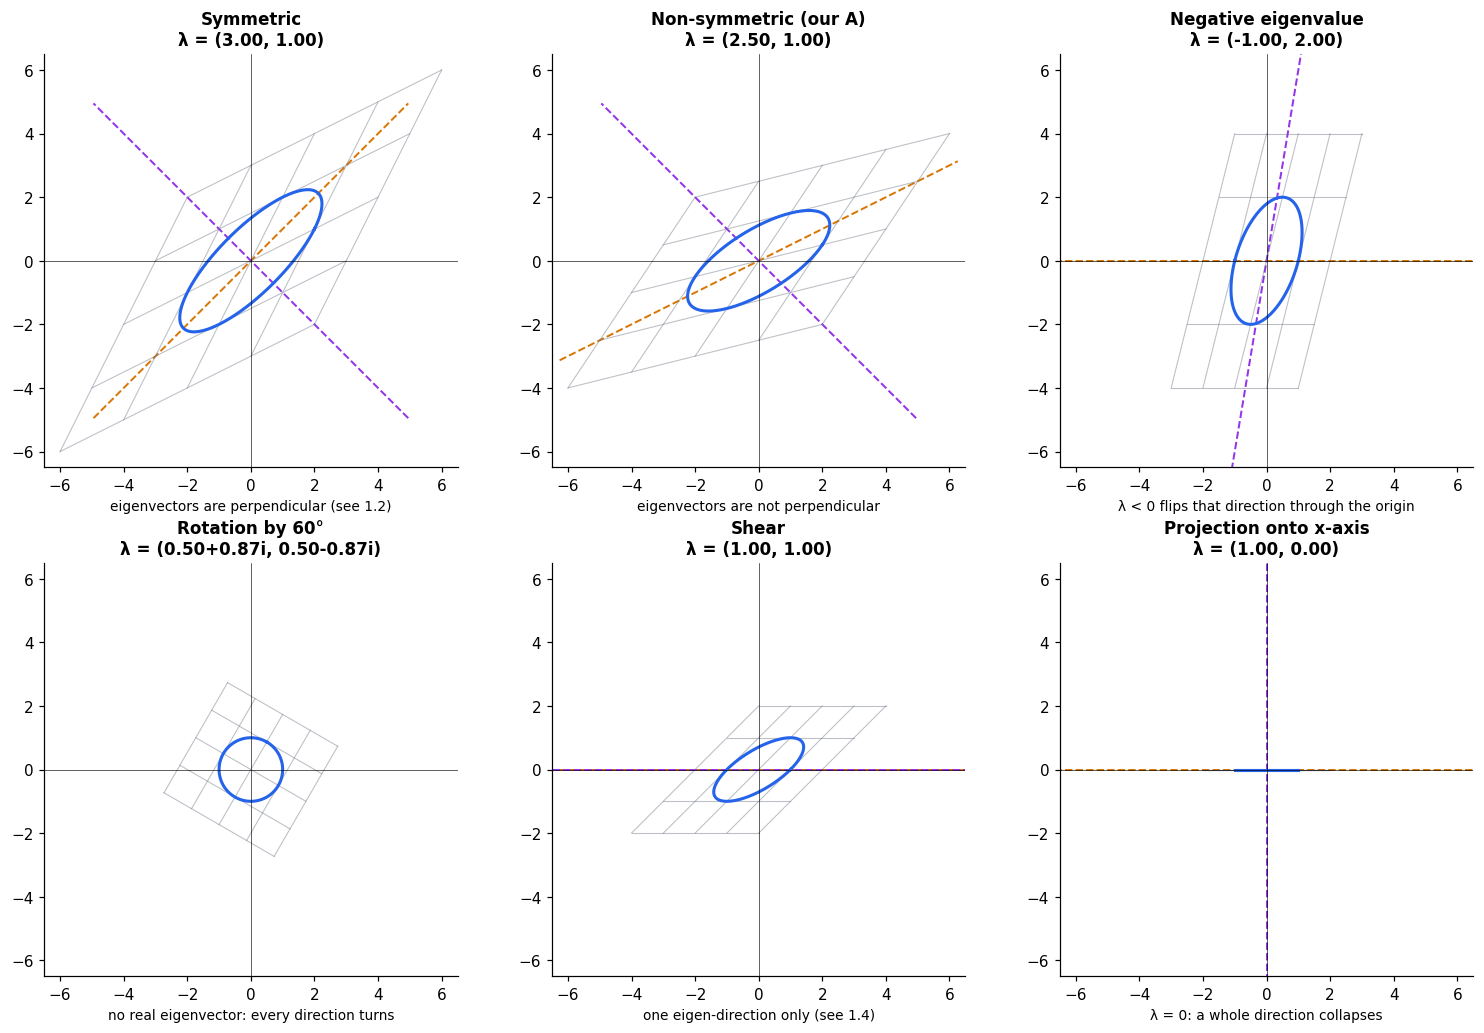

In [20]:
def fmt(z):
    z = complex(z)
    return f"{z.real:.2f}" if abs(z.imag) < 1e-9 else f"{z.real:.2f}{z.imag:+.2f}i"


a60 = math.radians(60)
gallery = [
    ("Symmetric",              torch.tensor([[2.0, 1.0], [1.0, 2.0]]),   "eigenvectors are perpendicular (see 1.2)"),
    ("Non-symmetric (our A)",  A,                                         "eigenvectors are not perpendicular"),
    ("Negative eigenvalue",    torch.tensor([[-1.0, 0.5], [0.0, 2.0]]),   "λ < 0 flips that direction through the origin"),
    ("Rotation by 60°",        torch.tensor([[math.cos(a60), -math.sin(a60)],
                                             [math.sin(a60),  math.cos(a60)]]), "no real eigenvector: every direction turns"),
    ("Shear",                  torch.tensor([[1.0, 1.0], [0.0, 1.0]]),    "one eigen-direction only (see 1.4)"),
    ("Projection onto x-axis", torch.tensor([[1.0, 0.0], [0.0, 0.0]]),    "λ = 0: a whole direction collapses"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 9.4))
for ax, (name, M, note) in zip(axes.flat, gallery):
    w, U = torch.linalg.eig(M)
    draw_space(ax, M, f"{name}\nλ = ({fmt(w[0])}, {fmt(w[1])})")
    if w.imag.abs().max() < 1e-9:
        draw_eigenlines(ax, U.real)
    ax.set_xlabel(note, fontsize=9)
plt.tight_layout(); plt.show()

## Step 9 · Repeated application: the dominant eigenvector wins

One more consequence of the eigenbasis, and a preview of how eigenvectors are computed in practice. Write a starting vector as $x = c_1 v_1 + c_2 v_2$. Then applying $A$ $k$ times gives

$$A^k x = c_1 \lambda_1^k\, v_1 + c_2 \lambda_2^k\, v_2$$

Whichever eigenvalue is larger in magnitude takes over, and the direction of $A^k x$ swings toward $v_1$. The angle to $v_1$ should shrink by roughly a factor of $|\lambda_2 / \lambda_1|$ per step, here $1/2.5 = 0.4$. This is the idea behind power iteration. Let's check the prediction.

measured shrink factor per step: 0.399      predicted |λ₂/λ₁|: 0.400


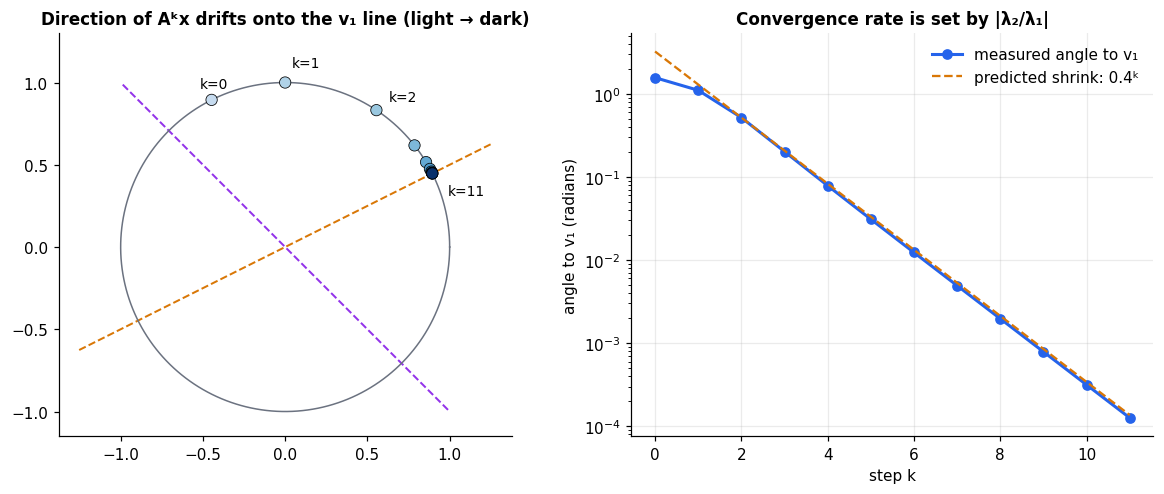

In [21]:
x = torch.tensor([-1.0, 2.0])          # an arbitrary start; not an eigenvector
v_dom = V[:, 0]                        # eigenvector of the largest eigenvalue

traj, angle_err = [], []
for k in range(12):
    xn = x / x.norm()
    traj.append(xn)
    cross = xn[0] * v_dom[1] - xn[1] * v_dom[0]
    angle_err.append(torch.atan2(cross.abs(), (xn @ v_dom).abs()).item())   # angle to the v₁ line
    x = A @ x

ratio = (lam[1].abs() / lam[0].abs()).item()
steps = len(angle_err) - 1
slope = (math.log(angle_err[-1]) - math.log(angle_err[4])) / (steps - 4)
print(f"measured shrink factor per step: {math.exp(slope):.3f}      predicted |λ₂/λ₁|: {ratio:.3f}")
assert abs(math.exp(slope) - ratio) < 0.02

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

ax = axes[0]
ax.plot(circle[0], circle[1], color=C_IN, lw=1)
draw_eigenlines(ax, V, length=1.4)
pts = torch.stack(traj)
shade = 0.25 + 0.75 * torch.arange(len(pts)) / (len(pts) - 1)       # light = early, dark = late
ax.scatter(pts[:, 0], pts[:, 1], c=plt.cm.Blues(shade.numpy()),
           s=55, edgecolors="black", linewidths=0.5, zorder=5)
for k, offset in [(0, (-8, 8)), (1, (4, 10)), (2, (8, 6)), (len(pts) - 1, (10, -14))]:
    ax.annotate(f"k={k}", xy=pts[k].tolist(), xytext=offset, textcoords="offset points", fontsize=9)
ax.set_ylim(-1.15, 1.3)
ax.set_aspect("equal"); ax.grid(False)
ax.set_title("Direction of Aᵏx drifts onto the v₁ line (light → dark)")

ax = axes[1]
ks = torch.arange(len(angle_err))
err = torch.tensor(angle_err)
ax.semilogy(ks, err, "o-", color=C_OUT, lw=2, label="measured angle to v₁")
ax.semilogy(ks, err[2] * ratio ** (ks - 2), "--", color=C_V1, lw=1.5, label=f"predicted shrink: {ratio:.1f}ᵏ")
ax.set_xlabel("step k"); ax.set_ylabel("angle to v₁ (radians)")
ax.set_title("Convergence rate is set by |λ₂/λ₁|")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Try it yourself

1. **Predict, then check.** For $A = \begin{pmatrix} 3 & 0 \\ 0 & 1 \end{pmatrix}$, what are the eigenvectors and eigenvalues? Write your guess down first, then run Steps 4 and 5 with this matrix.
2. **Break the search.** Set $A$ to a 90° rotation, $\begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$, and rerun Step 4. What does the deflection curve look like, and what does it tell you about eigenvectors?
3. **Build to order.** Use `from_eigen` to construct a matrix with eigenvectors $(1, 0)$ and $(1, 1)$ and eigenvalues $3$ and $0.5$. Verify with `torch.linalg.eig` that you get them back.
4. **Slow it down.** In Step 9, choose a matrix whose two eigenvalues are close in magnitude, such as 2.5 and 2.2. How many steps does it take to align, and how does that compare to $|\lambda_2/\lambda_1|^k$?

## What to carry forward

- A matrix is a linear function. Its columns are the images of the basis vectors.
- An **eigenvector** is a direction the matrix only scales, and the **eigenvalue** is that scale factor, sign included.
- In the basis of its eigenvectors, a matrix is just independent scalings: $A = V\Lambda V^{-1}$.
- This fails in instructive ways: rotations have complex eigenvalues, shears are missing an eigen-direction, and for a general matrix the eigenvectors are not perpendicular.
- A different basis can make the same transformation look simple or complicated. Keep this in mind, because it is the central difficulty when we try to interpret a network's internal directions.

**Next, notebook 1.2:** the spectral theorem, which says what changes when the matrix is symmetric.